In [1]:

!pip install -q ultralytics


In [2]:

import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO
from google.colab import files

print("Libraries imported successfully!")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Libraries imported successfully!


In [3]:

print("=" * 60)
print("       VISIONPORT OBJECT DETECTION SYSTEM")
print("=" * 60)


       VISIONPORT OBJECT DETECTION SYSTEM


In [4]:

print("Upload a real photograph...")

uploaded = files.upload()

image_path = list(uploaded.keys())[0]

print("Image uploaded successfully:", image_path)


Upload a real photograph...


Saving photo_6323421023977542514_y.jpg to photo_6323421023977542514_y.jpg
Image uploaded successfully: photo_6323421023977542514_y.jpg


In [5]:

print("Loading YOLOv8 pretrained model...")

model = YOLO("yolov8n.pt")

print("Model loaded successfully!")


Loading YOLOv8 pretrained model...
Model loaded successfully!


In [6]:

image = cv2.imread(image_path)

if image is None:
    raise ValueError("Image could not be loaded!")

image_rgb = cv2.cvtColor(
    image,
    cv2.COLOR_BGR2RGB
)

print("Image Acquisition Completed")
print("Original Image Size:", image_rgb.shape)


Image Acquisition Completed
Original Image Size: (886, 1216, 3)


In [7]:

print("Performing Object Detection...")

results = model.predict(
    source=image_path,
    conf=0.25,
    imgsz=640,
    verbose=False
)

print("Object detection completed!")


Performing Object Detection...
Object detection completed!


In [8]:

output_image = results[0].plot()

output_image = cv2.cvtColor(
    output_image,
    cv2.COLOR_BGR2RGB
)

print("Bounding boxes generated successfully!")


Bounding boxes generated successfully!


In [9]:

print("OBJECT DETECTION RESULTS")
print("-" * 50)

boxes = results[0].boxes

if boxes is not None and len(boxes) > 0:

    for i, box in enumerate(boxes):

        class_id = int(box.cls[0])
        confidence = float(box.conf[0])

        object_name = model.names[class_id]

        x1, y1, x2, y2 = map(
            int,
            box.xyxy[0]
        )

        print(f"{i+1}. Object: {object_name}")
        print(f"   Confidence: {confidence*100:.2f}%")
        print(f"   Bounding Box: ({x1}, {y1}, {x2}, {y2})")

else:
    print("No objects detected.")


OBJECT DETECTION RESULTS
--------------------------------------------------
1. Object: car
   Confidence: 78.87%
   Bounding Box: (508, 603, 645, 722)
2. Object: car
   Confidence: 68.26%
   Bounding Box: (71, 610, 216, 731)
3. Object: car
   Confidence: 68.25%
   Bounding Box: (996, 552, 1132, 666)
4. Object: person
   Confidence: 68.04%
   Bounding Box: (347, 815, 420, 886)
5. Object: car
   Confidence: 62.10%
   Bounding Box: (31, 690, 176, 835)
6. Object: bus
   Confidence: 61.17%
   Bounding Box: (759, 413, 943, 594)
7. Object: car
   Confidence: 55.61%
   Bounding Box: (467, 523, 570, 603)
8. Object: truck
   Confidence: 54.29%
   Bounding Box: (602, 716, 780, 883)
9. Object: truck
   Confidence: 54.23%
   Bounding Box: (218, 517, 328, 663)
10. Object: person
   Confidence: 53.27%
   Bounding Box: (140, 742, 199, 818)
11. Object: car
   Confidence: 43.42%
   Bounding Box: (189, 502, 267, 585)
12. Object: car
   Confidence: 42.10%
   Bounding Box: (674, 574, 836, 718)
13. Object: 

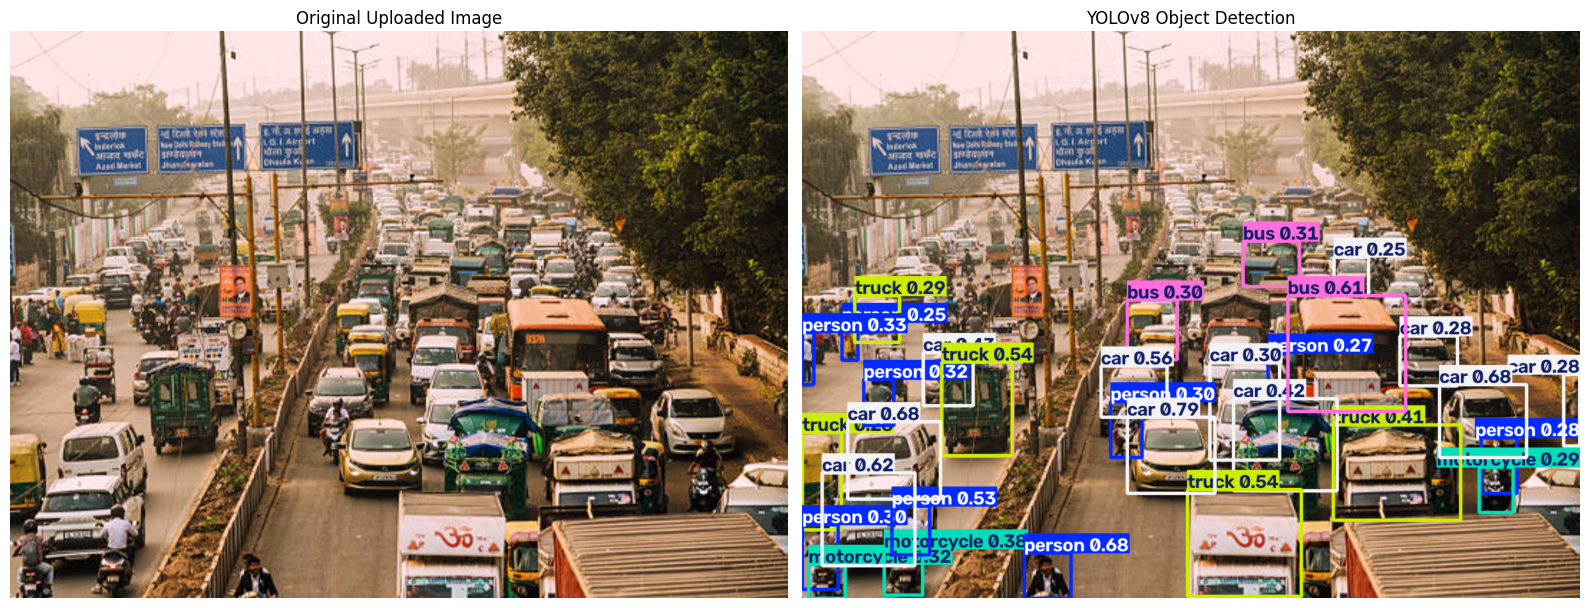

In [10]:

plt.figure(figsize=(16, 8))

plt.subplot(1, 2, 1)
plt.imshow(image_rgb)
plt.title("Original Uploaded Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(output_image)
plt.title("YOLOv8 Object Detection")
plt.axis("off")

plt.tight_layout()
plt.show()
